# Wide-band inverse scattering: inversion by frequency sweep

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Forgotten/jax-lippmann-schwinger/blob/main/notebooks/wideband_inversion_notebook.ipynb)

This is the multi-frequency companion to
[`full_waverform_inversion_notebook.ipynb`](full_waverform_inversion_notebook.ipynb).
That notebook inverts near-field data at a **single** frequency. Here we use data at
**several** frequencies and invert them one after another, from the lowest to the highest,
using each reconstruction as the starting guess for the next.

The reason to bother is that the single-frequency problem is only easy when the contrast is
weak. We will see a case where inverting the highest frequency directly ends up **worse than
the zero initial guess**, while the sweep recovers the medium with the same number of
optimiser updates and less wall-clock time.

In [11]:
# On Colab the package is not present, so install it from GitHub.
# Running from a local clone this cell does nothing.
#
# --no-cache-dir and --upgrade matter: without them pip can decide the already
# installed jax-ls satisfies the requirement and silently keep an older build,
# which then fails later with a missing attribute.
import importlib
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("google.colab") is not None:
  subprocess.run(
    [
      sys.executable,
      "-m",
      "pip",
      "install",
      "-q",
      "--no-cache-dir",
      "--upgrade",
      "git+https://github.com/Forgotten/jax-lippmann-schwinger.git@main",
    ],
    check=True,
  )
  # Fail here with a clear message rather than deep in a later cell.
  importlib.invalidate_caches()
  import jax_ls

  importlib.reload(jax_ls)
  missing = [n for n in ("Domain", "frequency_sweep") if not hasattr(jax_ls, n)]
  if missing:
    raise RuntimeError(
      "jax_ls installed but missing %s -- an older build is still loaded. "
      "Use Runtime > Restart session, then run this cell again." % missing
    )

In [12]:
# From a local clone, `context` puts the repository root on the path so that the
# library can be imported without installing it. On Colab it was installed above
# and there is no `context` module, so the import is optional.
try:
  import context
except ImportError:
  pass

import time

import matplotlib.pyplot as plt
import numpy as np

import jax
import jax.numpy as jnp

import jax_ls

# 64-bit arithmetic. The truncated Green's kernel is evaluated near a removable
# singularity, and the adjoint identities are checked to ~1e-15 in the test
# suite; single precision throws that away.
jax.config.update("jax_enable_x64", True)

Array = jax.Array

## 1. The forward problem

Exactly as in the single-frequency notebook. A compactly supported contrast $\nu$ scatters a
time-harmonic incident field $u_i$ at angular frequency $\omega$, and the scattered field
$u_s$ satisfies

$$\Delta u_s + \omega^2 (1+\nu)\, u_s = -\omega^2 \nu\, u_i ,$$

together with the Sommerfeld radiation condition. Introducing the *induced source*
$\sigma = \omega^2 \nu\,(u_i + u_s)$ and the volume potential $\mathcal{G}$ of the outgoing
fundamental solution, $\Delta G + \omega^2 G = -\delta$, this becomes the
**Lippmann–Schwinger equation**

$$(-I + \omega^2 \nu\, \mathcal{G})\,\sigma = -\omega^2 \nu\, u_i ,
\qquad u_s = \mathcal{G}\sigma .$$

$\mathcal{G}$ is applied by FFT in $O(N\log N)$ using the truncated kernel of Vico, Greengard
and Ferrando, and the equation is solved with GMRES.

The **near-field map** places point sources on a circle and measures the scattered field on a
circle,

$$F_\omega[\nu]_{s,r} \;=\; u_s^{(s)}(x_r),$$

a matrix indexed by (source, receiver). Note that everything in it depends on $\omega$: the
kernel, the incident fields, and the sampling. **So the data is per-frequency**, and — as we
will see — its shape changes with frequency too.

## 2. Why one frequency is not enough

Two facts pull in opposite directions.

**Resolution grows with frequency.** To leading order the linearised map has kernel
$\exp\!\big(i\omega(\hat s-\hat r)\cdot x\big)$, and since $\hat s,\hat r$ are unit vectors,
$|\omega(\hat s - \hat r)| \le 2\omega$. So an experiment at frequency $\omega$ carries **no
information** about spatial frequencies of $\nu$ above

$$|\xi| \le 2\omega ,$$

the half-wavelength diffraction limit: features finer than $\lambda/2$ are invisible. Low
frequency means a blurry reconstruction — of the medium in §3, the lowest stage can see the
broad Gaussian and nothing of the fine ones.

**But the basin of attraction shrinks with frequency.** The misfit is non-convex, and its
local minima are spaced roughly half a wavelength apart — *cycle skipping*. At high frequency
an initial guess must already be within about $\lambda/2$ of the truth, which a zero initial
guess generally is not.

**Frequency continuation** resolves this. Solve at a low frequency, where the landscape is
smooth and nearly convex but the answer is blurry; use that as the starting guess one
frequency up; repeat. Each step only has to move the iterate a little, so it stays inside the
basin.

This is the multiscale argument of Bunks et al. (1995) in seismic waveform inversion. In
inverse scattering the same idea is *recursive linearization*, introduced by **Chen (1997)**,
who observed that solving the nonlinear equations in order of increasing wavenumber reduces
them to a sequence of essentially linear problems; its convergence was analysed by **Bao and
Triki (2010)**. The specific algorithm followed here — the schedule, the band-limiting and the
sampling rules below — is that of **Borges, Gillman and Greengard (2017)**.

## 3. The medium

A shared `Domain` — one grid for the whole sweep, sized for the *highest* frequency, so the
contrast never has to be interpolated between stages.

The target is **multi-scale**, and deliberately so:

- a **broad** Gaussian, width $\approx 0.14$, which is the only part a low frequency can see;
- three **fine** Gaussians, width $\approx 0.03$, which only the highest frequency resolves.

The broad component is what makes a single frequency fail, and it does so at a *modest*
contrast. A wave crossing the medium picks up an extra phase of roughly

$$\Delta\phi \;\approx\; \frac{\omega}{2}\int \nu \,d\ell
  \;=\; \frac{\omega A}{2}\sqrt{\frac{\pi}{w}}$$

for a Gaussian of amplitude $A$ and width parameter $w$. Cycle skipping sets in once
$\Delta\phi \gtrsim \pi$. Here that is $\approx 4$ rad at $\omega_{\max}$ — comfortably
skipped — with a peak contrast of only $0.74$. Fine features, by contrast, contribute almost
no accumulated phase however tall they are, which is why a target of *only* narrow bumps needs
an implausibly large contrast before a single frequency struggles.

grid           48 x 48  (2304 unknowns)
grid spacing   hx = ax/n = 0.02083
peak contrast  0.74


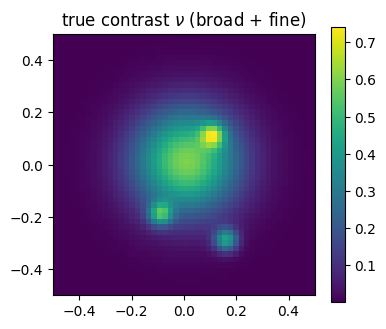

In [13]:
AX = AY = 1.0  # domain [-1/2, 1/2]^2
N = M = 48  # grid points per dimension
RADIUS = 1.5  # radius of the source / receiver circles

domain = jax_ls.Domain(AX, AY, N, M)


def perturbation(x: Array, y: Array) -> Array:
  """A multi-scale lens: one broad Gaussian plus three fine ones."""
  broad = 0.6 * jnp.exp(-25 * (jnp.square(x) + jnp.square(y)))
  fine = 0.4 * (
    jnp.exp(-500 * (jnp.square(x + 0.10) + jnp.square(y + 0.20)))
    + jnp.exp(-500 * (jnp.square(x - 0.10) + jnp.square(y - 0.10)))
    + jnp.exp(-500 * (jnp.square(x - 0.15) + jnp.square(y + 0.30)))
  )
  return broad + fine


# `domain.sample` evaluates on the grid and flattens, replacing the
# fn(params.X, params.Y).reshape(-1) idiom.
nu_true = domain.sample(perturbation)

print("grid           %d x %d  (%d unknowns)" % (N, M, domain.n_dof))
print("grid spacing   hx = ax/n = %.5f" % domain.hx)
print("peak contrast  %.2f" % float(jnp.max(nu_true)))

plt.figure(figsize=(4, 3.4))
plt.imshow(
  domain.grid(nu_true),
  extent=[-AX / 2, AX / 2, -AY / 2, AY / 2],
  origin="lower",
)
plt.colorbar()
plt.title("true contrast $\\nu$ (broad + fine)")
plt.tight_layout()
plt.show()

## 4. The sweep schedule

A sweep is a list of stages, each a **frequency** and a **maximum number of optimiser
updates**. `jax_ls` accepts the most convenient form — here a `{frequency: max_updates}`
dict, sorted ascending internally because a sweep must start low.

We take the top frequency at 8 points per wavelength on this grid,

$$\omega_{\max} = 2\pi \cdot \frac{n}{8},$$

and place two lower stages at $\omega_{\max}/4$ and $\omega_{\max}/2$.

### How many sources and receivers?

Not a free choice, and not a new observation. A scattered field is quasi-bandlimited, and its
degrees of freedom are essentially the Nyquist number for that effective spatial bandwidth
(**Bucci and Franceschetti, 1989**), so sampling a *field* more finely than that adds nothing.
Carrying this into the *inverse* problem, **Bucci and Isernia (1997)** show that only a
finite-dimensional part of the contrast is retrievable at all, bound that dimension for both
single-view and multiview experiments, and give schemes that collect the available information
without redundancy. That is the result behind how many illuminations *and* how many receivers
are worth using: below it you throw information away, above it you only pay for solves.

Borges, Gillman and Greengard turn that into the concrete counts used here,

$$N_{\text{src}} \approx \frac{2\omega a}{\pi}, \qquad
  N_{\text{recv}} \approx \frac{4\omega a}{\pi},$$

which matches the count of independent measurements $N_{\text{src}}N_{\text{recv}} =
O(\omega^2)$ to the number of recoverable unknowns inside the band $|\xi|\le 2\omega$, also
$O(\omega^2)$. `jax_ls` applies this rule automatically. It is also why the sweep is *cheap*:
the cost of a solve is linear in the number of sources, so the low-frequency stages are
nearly free.

In [14]:
OMEGA_MAX = 2 * np.pi * (N // 8)  # 8 points per wavelength on this grid

# frequency -> maximum number of BFGS updates at that frequency.
# Five stages, not three: the broad component accumulates about 4 radians of
# phase at the top frequency, so the band has to be opened gradually enough that
# each stage starts inside its own basin.
stages = {
  OMEGA_MAX / 4.0: 15,
  OMEGA_MAX / 2.8: 15,
  OMEGA_MAX / 2.0: 15,
  OMEGA_MAX / 1.4: 15,
  OMEGA_MAX: 25,
}
TOTAL_UPDATES = sum(stages.values())

rule = jax_ls.FrequencySchedule(omegas=jnp.asarray(sorted(stages)))

print(
  "%-9s %-6s %-8s %-10s %-12s %s"
  % ("omega", "ppw", "sources", "receivers", "band |j|<=", "recoverable dof")
)
for omega in sorted(stages):
  ppw = 2 * np.pi * N / omega
  print(
    "%-9.2f %-6.1f %-8d %-10d %-12.1f %d of %d"
    % (
      omega,
      ppw,
      rule.n_sources_for(domain, omega),
      rule.n_receivers_for(domain, omega),
      jax_ls.band_index(domain, omega),
      jax_ls.band_dimension(domain, omega),
      domain.n_dof,
    )
  )
print()
print("total update budget:", TOTAL_UPDATES)

omega     ppw    sources  receivers  band |j|<=   recoverable dof
9.42      32.0   6        12         3.0          29 of 2304
13.46     22.4   9        18         4.3          61 of 2304
18.85     16.0   12       24         6.0          113 of 2304
26.93     11.2   18       35         8.6          233 of 2304
37.70     8.0    24       48         12.0         441 of 2304

total update budget: 85


Notice the last two columns. At the lowest frequency only a few dozen of the 2304 grid
unknowns are inside the resolvable band; by the top frequency it is a few hundred. **That is
the resolution the data supports** — asking for more is fitting noise, and it is why a
reconstruction should never be claimed below $\lambda/2$.

## 5. The data

Synthetic here: we evaluate the forward map at the true contrast, once per frequency. With
real measurements this callback would look the data up instead.

Because the sampling rule grows with $\omega$, **each frequency's data matrix has a different
shape** — so a wide-band dataset is a list, not an array, and the frequencies cannot be
batched together.

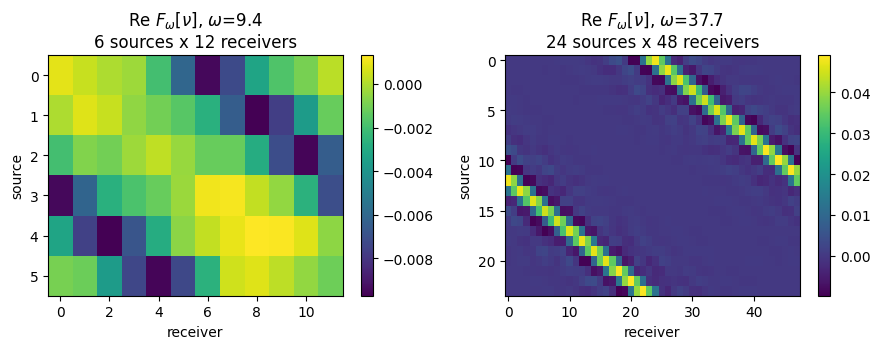

In [15]:
def data_for(params) -> Array:
  """The measured near field at one frequency.

  Called once per stage by the sweep, with that frequency's parameters.
  """
  return jax_ls.near_field_map(params, nu_true)


# Look at the data at the lowest and highest frequency.
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, omega in zip(axes, [min(stages), max(stages)]):
  params = jax_ls.make_sweep_params(domain, omega, RADIUS)
  data = data_for(params)
  im = ax.imshow(jnp.real(data), aspect="auto")
  ax.set_title(
    "Re $F_\\omega[\\nu]$, $\\omega$=%.1f\n%d sources x %d receivers"
    % (omega, params.n_sources, params.n_receivers)
  )
  ax.set_xlabel("receiver")
  ax.set_ylabel("source")
  plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 6. The misfit

At each frequency we minimise the same least-squares misfit as the single-frequency notebook,

$$\ell_\omega(\nu) \;=\; \tfrac12\big\|F_\omega[\nu] - D_\omega\big\|_F^2 ,$$

whose gradient comes from the adjoint-state method: one extra linear solve, not a tape
through GMRES. The outer optimiser is **BFGS**.

### An aside on weighting

If instead you minimised all frequencies *at once*, you could not simply add the terms. The
data amplitude grows with frequency — measured on this code, $\|F_\omega\|\sim\omega^{0.43}$
and $\|\nabla\ell_\omega\|\sim\omega^{0.9}$, neither a clean power — so an unweighted sum is
dominated by the highest frequency. The robust fix is to normalise by the measured data norm,

$$\ell(\nu) = \sum_k w_k\,\tfrac12\big\|F_{\omega_k}[\nu]-D_k\big\|_F^2,
\qquad w_k = \frac{1}{\|D_k\|_F^2},$$

available as `jax_ls.Weighting.DATA_NORM` for `jax_ls.wideband_minimize`.

**In a sequential sweep this does not arise**: one frequency is active at a time, and scaling
a single-frequency objective changes neither its minimiser nor the step. One more reason to
prefer continuation.

## 7. Run the sweep

`frequency_sweep` walks the stages in increasing frequency, carrying the reconstruction
forward as the next initial guess.

In [16]:
start = time.time()
result_sweep = jax_ls.frequency_sweep(
  domain,
  stages,
  data_for,
  radius=RADIUS,
  nu0=jnp.zeros(domain.n_dof),  # start from nothing
)
time_sweep = time.time() - start

nu_sweep = result_sweep.nu
rel_sweep = float(
  jnp.linalg.norm(nu_sweep - nu_true) / jnp.linalg.norm(nu_true)
)
print()
print("sweep: relative model error %.4f in %.0f s" % (rel_sweep, time_sweep))

  omega    9.42  sources   6  receivers  12  misfit 2.9374e-03
  omega   13.46  sources   9  receivers  18  misfit 8.0555e-04
  omega   18.85  sources  12  receivers  24  misfit 1.4065e-04
  omega   26.93  sources  18  receivers  35  misfit 1.3318e-05
  omega   37.70  sources  24  receivers  48  misfit 4.5784e-06

sweep: relative model error 0.0177 in 54 s


## 8. The baseline: the top frequency on its own

The same optimiser, the same total number of updates, the same zero start — but only the
highest frequency, which is what the single-frequency notebook does.

In [ ]:
params_top = jax_ls.make_sweep_params(domain, OMEGA_MAX, RADIUS)

start = time.time()
result_single = jax_ls.minimize(
  params_top,
  data_for(params_top),
  jnp.zeros(domain.n_dof),
  jax_ls.QuasiNewton(maxiter=TOTAL_UPDATES),  # same budget as the whole sweep
)
time_single = time.time() - start

nu_single = result_single.nu
rel_single = float(
  jnp.linalg.norm(nu_single - nu_true) / jnp.linalg.norm(nu_true)
)

print(
  "single frequency: relative model error %.4f in %.0f s"
  % (rel_single, time_single)
)
print()
print("%-18s %-14s %s" % ("", "model error", "time"))
print("%-18s %-14.4f %.0f s" % ("sweep", rel_sweep, time_sweep))
print("%-18s %-14.4f %.0f s" % ("single frequency", rel_single, time_single))
print()
if rel_single > 1.0:
  print("A relative error above 1 means the single-frequency reconstruction is")
  print(
    "WORSE than the zero initial guess it started from -- it cycle-skipped."
  )

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
extent = [-AX / 2, AX / 2, -AY / 2, AY / 2]
vmax = float(jnp.max(nu_true))

for ax, (field, title) in zip(
  axes,
  [
    (nu_true, "true $\\nu$"),
    (nu_sweep, "sweep (err %.3f)" % rel_sweep),
    (nu_single, "single freq (err %.3f)" % rel_single),
  ],
):
  im = ax.imshow(
    domain.grid(field), extent=extent, origin="lower", vmin=0, vmax=vmax
  )
  ax.set_title(title)
  ax.set_xticks([])
  ax.set_yticks([])
  plt.colorbar(im, ax=ax, fraction=0.046)

im = axes[3].imshow(
  domain.grid(jnp.abs(nu_sweep - nu_true)), extent=extent, origin="lower"
)
axes[3].set_title("|sweep - true|")
axes[3].set_xticks([])
axes[3].set_yticks([])
plt.colorbar(im, ax=axes[3], fraction=0.046)
plt.tight_layout()
plt.show()

## 9. What happened stage by stage

`result.history` records one entry per frequency. Read down the misfit column: each stage
starts from the previous reconstruction and improves on it, and with a fine enough ladder the
misfit falls monotonically.

That monotonicity is not guaranteed — each stage measures a *different* misfit, against more
data at a higher frequency, so a stage that starts outside its basin can report a larger
number than the one before it. Seeing it rise is the signal to add intermediate frequencies.

The reconstruction fills in by scale: the first stages recover the broad Gaussian, which is
all their band contains, and only the last stages resolve the three fine bumps.

In [ ]:
print(
  "%-9s %-8s %-10s %-13s %s"
  % ("omega", "sources", "receivers", "max updates", "final misfit")
)
for record in result_sweep.history:
  print(
    "%-9.2f %-8d %-10d %-13d %.4e"
    % (
      record["omega"],
      record["n_sources"],
      record["n_receivers"],
      record["max_updates"],
      record["loss"],
    )
  )

## 10. Variations

Everything above used the defaults. Three knobs worth knowing.

**Band-limiting.** Passing `band_factor=2.0` projects the estimate onto $|\xi|\le 2\omega$ on
entry to each stage, discarding modes the previous frequency could not have known. It is the
only regularisation Borges et al. use. Off by default here because BFGS with a bounded update
budget is already implicitly regularised; it matters more with Gauss–Newton, where
$J^H J$ is otherwise singular on the invisible modes.

**Gauss–Newton instead of BFGS.** `optimizer=jax_ls.GaussNewton(...)` takes a few
band-limited Gauss–Newton steps per stage, solving the normal equations
$J^H J\,\delta\nu = J^H r$ with **CG** — the right method there, since $J^HJ$ is Hermitian
positive semi-definite. (GMRES cannot be used on this operator: it needs a transposable
operator, and applying $J$ runs a GMRES solve internally.)

On this problem it lands in the same place as the BFGS sweep at comparable cost (0.017 vs
0.018), so neither is the obvious winner here. Gauss-Newton earns its keep when the per-stage
update budget is tight, since it extracts more from each linearisation than a gradient method
can; with a generous budget, as here, BFGS catches up.

**Simultaneous inversion.** `jax_ls.wideband_minimize` minimises all frequencies at once with
the data-norm weighting of §6 — best as a final polish over the top few frequencies, not as
the main path.

In [ ]:
# A band-limited Gauss-Newton sweep, for comparison. Fewer, more expensive steps.
start = time.time()
result_gn = jax_ls.frequency_sweep(
  domain,
  stages,
  data_for,
  radius=RADIUS,
  band_factor=2.0,  # project between stages
  optimizer=jax_ls.GaussNewton(
    n_steps=2,
    inner=jax_ls.NormalEquationsConfig(method="cg", n_iter=15),
    band_factor=2.0,
  ),
)
rel_gn = float(
  jnp.linalg.norm(result_gn.nu - nu_true) / jnp.linalg.norm(nu_true)
)
print()
print(
  "band-limited Gauss-Newton: relative model error %.4f in %.0f s"
  % (rel_gn, time.time() - start)
)

## References

**Recursive linearization**

- Y. Chen, *Inverse scattering via Heisenberg's uncertainty principle*, Inverse Problems
  **13**(2), 253–282 (1997),
  [doi:10.1088/0266-5611/13/2/005](https://doi.org/10.1088/0266-5611/13/2/005) — introduces
  recursive linearization: solved in order of increasing wavenumber, the nonlinear equations
  reduce to a collection of essentially linear ones.
- G. Bao and F. Triki, *Error estimates for the recursive linearization of inverse medium
  problems*, J. Comput. Math. **28**(6), 725–744 (2010) — convergence analysis of the
  algorithm with multi-frequency data.
- C. Borges, A. Gillman and L. Greengard, *High resolution inverse scattering in two
  dimensions using recursive linearization*, SIAM J. Imaging Sci. **10**(2), 641–664 (2017),
  [arXiv:1608.06871](https://arxiv.org/abs/1608.06871) — the frequency schedule, the
  band-limiting, and the concrete $O(\omega)$ sampling counts used above.

**How much information the data carries**

- O. M. Bucci and G. Franceschetti, *On the degrees of freedom of scattered fields*, IEEE
  Trans. Antennas Propag. **37**(7), 918–926 (1989),
  [doi:10.1109/8.29386](https://doi.org/10.1109/8.29386) — a scattered field is
  quasi-bandlimited, and its degrees of freedom are the Nyquist number of that effective
  spatial bandwidth. This is the *field* side: how finely to sample one measurement curve.
- O. M. Bucci and T. Isernia, *Electromagnetic inverse scattering: retrievable information and
  measurement strategies*, Radio Science **32**(6), 2123–2137 (1997),
  [doi:10.1029/97RS01826](https://doi.org/10.1029/97RS01826) — the *inverse* side: only a
  finite-dimensional part of the contrast is retrievable, with bounds on that dimension for
  single-view and multiview experiments and nonredundant measurement schemes. This is what
  dictates the source and receiver counts of §4.

**Forward solver and multiscale continuation**
- F. Vico, L. Greengard and M. Ferrando, *Fast convolution with free-space Green's
  functions*, J. Comput. Phys. **323**, 191–203 (2016),
  [arXiv:1604.03155](https://arxiv.org/abs/1604.03155) — the truncated kernel behind
  `apply_green_function`.
- C. Bunks, F. M. Saleck, S. Zaleski and G. Chavent, *Multiscale seismic waveform inversion*,
  Geophysics **60**(5), 1457–1473 (1995) — the multiscale / cycle-skipping argument.
- L. Sirgue and R. G. Pratt, *Efficient waveform inversion and imaging: a strategy for
  selecting temporal frequencies*, Geophysics **69**(1), 231–248 (2004) — why a sparse,
  geometrically spaced set of frequencies suffices.